# Canadian Data Analyst Job Market Analysis (Job Bank postings, Jan 2025 - Aug 2026)

All the code we built so far, in the order it was run, with comments. Cells are grouped into parts:

0. Setup
1. Inspecting the raw files (encoding / separator / header bug)
2. The reusable loader `load_one_file()`
3. Combining and filtering all 20 months into `combined_full`
4. Task 2: postings trend (the original 11-month analysis, Oct 2025 - Aug 2026)
5. Salary analysis (11 months)
6. Does job-title mix explain the salary rise?
7. Extending to 20 months: schema check, volume vs. total postings, and the informatics-pool split

Note: parts 4 and 5 were first run on the 11-month data (Oct 2025 - Aug 2026). In this notebook they use `files_11` / `combined`, which are the same 11 months, so the numbers match what you saw.

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Folder holding all 20 monthly Job Bank CSV exports (Jan 2025 - Aug 2026)
data_folder = Path('/Users/abinashkanagalingam/Downloads/DA_Job_Postings')

# glob('*.csv') finds every CSV in the folder; sorted() puts them in a stable order
files = sorted(data_folder.glob('*.csv'))
print(f"Total files found: {len(files)}")

# Quick look at each file: name, extension, and size in MB (a very different size can signal a different format)
for f in files:
    print(f"{f.name:20} {f.suffix:6} {f.stat().st_size / 1_000_000:.1f} MB")

Total files found: 20
apr_2025.csv         .csv   56.7 MB
april_2026.csv       .csv   47.4 MB
aug_2025.csv         .csv   48.3 MB
aug_2026.csv         .csv   24.1 MB
dec_2025.csv         .csv   33.5 MB
feb_2025.csv         .csv   75.4 MB
feb_2026.csv         .csv   39.4 MB
jan_2025.csv         .csv   82.0 MB
jan_2026.csv         .csv   23.0 MB
jul_2025.csv         .csv   49.6 MB
july_2026.csv        .csv   46.2 MB
jun_2025.csv         .csv   56.8 MB
june_2026.csv        .csv   24.6 MB
mar_2025.csv         .csv   70.8 MB
march_2026.csv       .csv   44.2 MB
may_2025.csv         .csv   57.9 MB
may_2026.csv         .csv   44.2 MB
nov_2025.csv         .csv   18.3 MB
oct_2025.csv         .csv   22.6 MB
sep_2025.csv         .csv   48.9 MB


## 1. Inspecting the raw files

The monthly exports are not all saved the same way. Some are UTF-8 with commas, some are UTF-16 with tabs, and the UTF-8 ones have a corrupted first column name (`ythWIC Job Location Snapshot ID`). These cells are how we found that out. They are diagnostic: you only need to re-run them if a new file misbehaves.

In [2]:
# Step 1: read the first 20 raw bytes of each file (binary mode, 'rb') to spot the BOM signature.
#   b'\xef\xbb\xbf' at the start = UTF-8 with BOM
#   b'\xff\xfe'     at the start = UTF-16 (little endian)
for f in files:
    with open(f, 'rb') as fh:
        print(f.name, fh.read(20))

apr_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
april_2026.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
aug_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
aug_2026.csv b'\xef\xbb\xbfythWIC Job Locati'
dec_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
feb_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
feb_2026.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
jan_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
jan_2026.csv b'\xef\xbb\xbfythWIC Job Locati'
jul_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
july_2026.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
jun_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
june_2026.csv b'\xef\xbb\xbfythWIC Job Locati'
mar_2025.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
march_2026.csv b'\xff\xfeW\x00I\x00C\x00 \x00J\x00o\x00b\x00 \x00L\x00'
may_2025.csv b'\

In [3]:
# Step 2: try to read each file's first line as UTF-8.
# UTF-16 files fail here with UnicodeDecodeError (byte 0xff is never a valid UTF-8 start byte).
for f in files:
    try:
        with open(f, encoding='utf-8') as fh:
            print(f.name, '->', fh.readline()[:80])
    except UnicodeDecodeError as e:
        print(f.name, '-> FAILED:', e)

apr_2025.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
april_2026.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
aug_2025.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
aug_2026.csv -> ﻿ythWIC Job Location Snapshot ID,Job Title,Original Job Title,NOC 2016 Code,NOC 
dec_2025.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
feb_2025.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
feb_2026.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
jan_2025.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
jan_2026.csv -> ﻿ythWIC Job Location Snapshot ID,Job Title,Original Job Title,NOC 2016 Code,NOC 
jul_2025.csv -> FAILED: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
july_2026.csv -> FAILED: 'utf-8' codec can't

In [4]:
# Step 3: same test as UTF-16. UTF-8 files fail here instead.
for f in files:
    try:
        with open(f, encoding='utf-16') as fh:
            print(f.name, '->', fh.readline()[:80])
    except UnicodeError as e:
        print(f.name, '-> FAILED:', e)

apr_2025.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
april_2026.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
aug_2025.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
aug_2026.csv -> FAILED: UTF-16 stream does not start with BOM
dec_2025.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
feb_2025.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
feb_2026.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
jan_2025.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
jan_2026.csv -> FAILED: UTF-16 stream does not start with BOM
jul_2025.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016
july_2026.csv -> WIC Job Location Snapshot ID	Job Title	Original Job Title	NOC 2016 Code	NOC 2016


In [5]:
# Step 4: record each file's encoding (decided by its first 2 bytes), then print the header line with repr().
# repr() shows hidden characters, so we can see whether columns are separated by \t (tab) or , (comma)
# and whether the first column name has the stray "yth" prefix.
encodings = {}
for f in files:
    with open(f, 'rb') as fh:
        first2 = fh.read(2)
    encodings[f.name] = 'utf-16' if first2 in (b'\xff\xfe', b'\xfe\xff') else 'utf-8-sig'

print(encodings)

for f in files:
    with open(f, encoding=encodings[f.name]) as fh:
        print(f.name, repr(fh.readline()[:100]))

{'apr_2025.csv': 'utf-16', 'april_2026.csv': 'utf-16', 'aug_2025.csv': 'utf-16', 'aug_2026.csv': 'utf-8-sig', 'dec_2025.csv': 'utf-16', 'feb_2025.csv': 'utf-16', 'feb_2026.csv': 'utf-16', 'jan_2025.csv': 'utf-16', 'jan_2026.csv': 'utf-8-sig', 'jul_2025.csv': 'utf-16', 'july_2026.csv': 'utf-16', 'jun_2025.csv': 'utf-16', 'june_2026.csv': 'utf-8-sig', 'mar_2025.csv': 'utf-16', 'march_2026.csv': 'utf-16', 'may_2025.csv': 'utf-16', 'may_2026.csv': 'utf-16', 'nov_2025.csv': 'utf-8-sig', 'oct_2025.csv': 'utf-8-sig', 'sep_2025.csv': 'utf-16'}
apr_2025.csv 'WIC Job Location Snapshot ID\tJob Title\tOriginal Job Title\tNOC 2016 Code\tNOC 2016 Code Name\tNOC21 Cod'
april_2026.csv 'WIC Job Location Snapshot ID\tJob Title\tOriginal Job Title\tNOC 2016 Code\tNOC 2016 Code Name\tNOC21 Cod'
aug_2025.csv 'WIC Job Location Snapshot ID\tJob Title\tOriginal Job Title\tNOC 2016 Code\tNOC 2016 Code Name\tNOC21 Cod'
aug_2026.csv 'ythWIC Job Location Snapshot ID,Job Title,Original Job Title,NOC 2016 Code,NOC 

In [6]:
# Step 5: load one file of each type with its confirmed settings and compare.
#   UTF-16 files -> tab separated; UTF-8 files -> comma separated
utf16_sample = 'april_2026.csv'
utf8_sample = 'aug_2026.csv'

df_utf16 = pd.read_csv(data_folder / utf16_sample, encoding='utf-16', sep='\t')
df_utf8 = pd.read_csv(data_folder / utf8_sample, encoding='utf-8-sig', sep=',')

print(utf16_sample)
print(df_utf16.shape)
print(list(df_utf16.columns)[:5])
print()
print(utf8_sample)
print(df_utf8.shape)
print(list(df_utf8.columns)[:5])

april_2026.csv
(53616, 65)
['WIC Job Location Snapshot ID', 'Job Title', 'Original Job Title', 'NOC 2016 Code', 'NOC 2016 Code Name']

aug_2026.csv
(53799, 65)
['ythWIC Job Location Snapshot ID', 'Job Title', 'Original Job Title', 'NOC 2016 Code', 'NOC 2016 Code Name']


In [7]:
# Step 6: confirm the "yth" header bug appears in several UTF-8 files (nrows=1 reads just the header + 1 row, fast).
utf8_files = ['aug_2026.csv', 'jan_2026.csv', 'june_2026.csv']

for name in utf8_files:
    df_temp = pd.read_csv(data_folder / name, encoding='utf-8-sig', sep=',', nrows=1)
    print(name, '->', df_temp.columns[0])

aug_2026.csv -> ythWIC Job Location Snapshot ID
jan_2026.csv -> ythWIC Job Location Snapshot ID
june_2026.csv -> ythWIC Job Location Snapshot ID


## 2. The reusable loader

One function that handles both file types: detects the encoding from the first 2 bytes, picks the matching separator, and fixes the `yth` prefix if it is there.

In [8]:
def load_one_file(filepath):
    # Detect encoding from the first 2 bytes (BOM signature)
    with open(filepath, 'rb') as fh:
        first2 = fh.read(2)
    encoding = 'utf-16' if first2 in (b'\xff\xfe', b'\xfe\xff') else 'utf-8-sig'

    # UTF-16 files are tab-separated, UTF-8 files are comma-separated
    sep = '\t' if encoding == 'utf-16' else ','

    # (Optional) add low_memory=False to silence the harmless "Columns (57,58) have mixed types" DtypeWarning
    df = pd.read_csv(filepath, encoding=encoding, sep=sep)

    # Fix the 'yth' prefix bug on the first column name, only if present
    first_col = df.columns[0]
    if first_col.startswith('yth'):
        df = df.rename(columns={first_col: first_col.replace('yth', '', 1)})

    return df

In [9]:
# Test the loader on every file: each should load, and the first column should be clean ("WIC Job Location Snapshot ID").
# 2025 files have 64 columns, 2026 files have 65.
for f in files:
    df = load_one_file(f)
    print(f.name, df.shape, '-> first column:', df.columns[0])

apr_2025.csv (68653, 64) -> first column: WIC Job Location Snapshot ID
april_2026.csv (53616, 65) -> first column: WIC Job Location Snapshot ID
aug_2025.csv (56776, 64) -> first column: WIC Job Location Snapshot ID
aug_2026.csv (53799, 65) -> first column: WIC Job Location Snapshot ID
dec_2025.csv (38075, 64) -> first column: WIC Job Location Snapshot ID
feb_2025.csv (94240, 64) -> first column: WIC Job Location Snapshot ID
feb_2026.csv (44176, 65) -> first column: WIC Job Location Snapshot ID
jan_2025.csv (101570, 64) -> first column: WIC Job Location Snapshot ID
jan_2026.csv (51178, 65) -> first column: WIC Job Location Snapshot ID
jul_2025.csv (58692, 64) -> first column: WIC Job Location Snapshot ID
july_2026.csv (51999, 65) -> first column: WIC Job Location Snapshot ID
jun_2025.csv (68793, 64) -> first column: WIC Job Location Snapshot ID
june_2026.csv (55091, 65) -> first column: WIC Job Location Snapshot ID
mar_2025.csv (87785, 64) -> first column: WIC Job Location Snapshot ID
m

/var/folders/x0/tnq06mms319gftqmck0wk0m80000gn/T/ipykernel_2286/267743930.py:11: DtypeWarning: Columns (57,58) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, encoding=encoding, sep=sep)


may_2026.csv (49961, 65) -> first column: WIC Job Location Snapshot ID
nov_2025.csv (42191, 64) -> first column: WIC Job Location Snapshot ID
oct_2025.csv (53724, 64) -> first column: WIC Job Location Snapshot ID
sep_2025.csv (58310, 64) -> first column: WIC Job Location Snapshot ID


## 3. Combine and filter all 20 months

"Data Analyst" is defined strictly as a title containing the text `data analyst` (case-insensitive). Adjacent roles (Business Analyst, BI Analyst, Data Scientist) are not mixed in.

In [10]:
def get_month_label_v2(filename):
    # Every file is named monthname_year.csv (e.g. 'march_2026.csv' or 'jan_2025.csv').
    # Split on '_', keep the first 3 letters of the month, and attach the year -> 'Mar 2026'.
    month_part, year = filename.replace('.csv', '').split('_')
    return month_part[:3].title() + ' ' + year

all_filtered_full = []

for f in files:
    df = load_one_file(f)                                            # load one monthly file
    mask = df['Job Title'].str.contains('data analyst', case=False, na=False)   # True where the title contains "data analyst"
    filtered = df.loc[mask, ['Job Title', 'NOC21 Code Name', 'Province/Territory', 'City',
                              'First Posting Date', 'Vacancy Count']].copy()   # keep only matching rows and 6 columns
    filtered.insert(0, 'Month', get_month_label_v2(f.name))          # add a readable Month column at the front
    print(f.name, '->', get_month_label_v2(f.name), '->', len(filtered), 'Data Analyst rows')
    all_filtered_full.append(filtered)

# Stack the 20 small tables into one, and add a real date column so months sort chronologically
combined_full = pd.concat(all_filtered_full, ignore_index=True)
combined_full['Month_Date'] = pd.to_datetime(combined_full['Month'], format='%b %Y')
print('\nTotal combined rows:', len(combined_full))

apr_2025.csv -> Apr 2025 -> 56 Data Analyst rows
april_2026.csv -> Apr 2026 -> 19 Data Analyst rows
aug_2025.csv -> Aug 2025 -> 15 Data Analyst rows
aug_2026.csv -> Aug 2026 -> 21 Data Analyst rows
dec_2025.csv -> Dec 2025 -> 26 Data Analyst rows
feb_2025.csv -> Feb 2025 -> 148 Data Analyst rows
feb_2026.csv -> Feb 2026 -> 16 Data Analyst rows
jan_2025.csv -> Jan 2025 -> 161 Data Analyst rows
jan_2026.csv -> Jan 2026 -> 23 Data Analyst rows
jul_2025.csv -> Jul 2025 -> 29 Data Analyst rows
july_2026.csv -> Jul 2026 -> 20 Data Analyst rows
jun_2025.csv -> Jun 2025 -> 48 Data Analyst rows
june_2026.csv -> Jun 2026 -> 18 Data Analyst rows
mar_2025.csv -> Mar 2025 -> 120 Data Analyst rows
march_2026.csv -> Mar 2026 -> 38 Data Analyst rows
may_2025.csv -> May 2025 -> 63 Data Analyst rows


/var/folders/x0/tnq06mms319gftqmck0wk0m80000gn/T/ipykernel_2286/267743930.py:11: DtypeWarning: Columns (57,58) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, encoding=encoding, sep=sep)


may_2026.csv -> May 2026 -> 17 Data Analyst rows
nov_2025.csv -> Nov 2025 -> 16 Data Analyst rows
oct_2025.csv -> Oct 2025 -> 26 Data Analyst rows
sep_2025.csv -> Sep 2025 -> 23 Data Analyst rows

Total combined rows: 903


In [11]:
# Sanity checks: no 'Unknown' labels, every month present
print(combined_full['Month'].value_counts())
combined_full.head(3)

Jan 2025    161
Feb 2025    148
Mar 2025    120
May 2025     63
Apr 2025     56
Jun 2025     48
Mar 2026     38
Jul 2025     29
Oct 2025     26
Dec 2025     26
Sep 2025     23
Jan 2026     23
Aug 2026     21
Jul 2026     20
Apr 2026     19
Jun 2026     18
May 2026     17
Feb 2026     16
Nov 2025     16
Aug 2025     15
Name: Month, dtype: int64


,Month,Job Title,NOC21 Code Name,Province/Territory,City,First Posting Date,Vacancy Count,Month_Date
0,Apr 2025,data analyst - informatics and systems,Database analysts and data administrators,Alberta,Edmonton,2025/04/04,1,2025-04-01
1,Apr 2025,big data analyst,Data scientists,Ontario,Sault Ste. Marie,2025/04/21,1,2025-04-01
2,Apr 2025,data analyst - informatics and systems,Database analysts and data administrators,Ontario,Woodbridge,2025/04/25,1,2025-04-01


In [12]:
# The original Task 2 and salary work used the 11 months Oct 2025 - Aug 2026.
# files_11 and combined recreate exactly that subset from the 20-month data.
files_11 = [f for f in files
            if pd.to_datetime(get_month_label_v2(f.name), format='%b %Y') >= pd.Timestamp('2025-10-01')]
combined = combined_full[combined_full['Month_Date'] >= '2025-10-01'].copy()

print(len(files_11), 'files,', len(combined), 'rows')   # expect 11 files, 240 rows

11 files, 240 rows


## 4. Task 2: postings trend over time (11 months, Oct 2025 - Aug 2026)

In [13]:
# One row per month with the number of Data Analyst postings.
#   groupby('Month_Date').size()  -> counts rows per month (a Series with Month_Date as its index)
#   .reset_index(name=...)        -> turns it back into a normal table with Month_Date as a column
monthly_counts = combined.groupby('Month_Date').size().reset_index(name='Posting_Count')
monthly_counts = monthly_counts.sort_values('Month_Date')

# .dt.strftime('%b %Y') turns the real date back into readable text ('Mar 2026') for chart labels
monthly_counts['Month_Label'] = monthly_counts['Month_Date'].dt.strftime('%b %Y')
monthly_counts

,Month_Date,Posting_Count,Month_Label
0,2025-10-01,26,Oct 2025
1,2025-11-01,16,Nov 2025
2,2025-12-01,26,Dec 2025
3,2026-01-01,23,Jan 2026
4,2026-02-01,16,Feb 2026
5,2026-03-01,38,Mar 2026
6,2026-04-01,19,Apr 2026
7,2026-05-01,17,May 2026
8,2026-06-01,18,Jun 2026
9,2026-07-01,20,Jul 2026


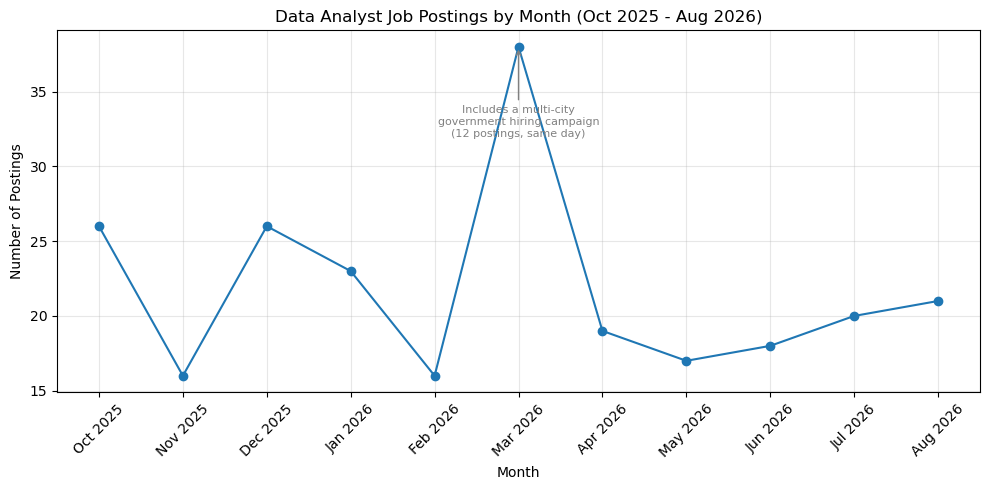

In [14]:
# Line chart of postings per month, with a callout on the March 2026 spike
plt.figure(figsize=(10, 5))
plt.plot(monthly_counts['Month_Label'], monthly_counts['Posting_Count'], marker='o')
plt.title('Data Analyst Job Postings by Month (Oct 2025 - Aug 2026)')
plt.xlabel('Month')
plt.ylabel('Number of Postings')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# annotate(text, xy=point the arrow points to, xytext=where the text sits)
plt.annotate('Includes a multi-city\ngovernment hiring campaign\n(12 postings, same day)',
             xy=('Mar 2026', 38), xytext=('Mar 2026', 32),
             ha='center', fontsize=8, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray'))

plt.tight_layout()
plt.show()

In [15]:
# Put a number on the direction: fit a straight line through the points.
# Month_Index is a simple numeric time axis (0 = Oct 2025 ... 10 = Aug 2026) because polyfit needs numbers.
monthly_counts['Month_Index'] = range(len(monthly_counts))

# np.polyfit(x, y, 1) fits a degree-1 polynomial (a straight line) by least squares and returns slope and intercept
slope, intercept = np.polyfit(monthly_counts['Month_Index'], monthly_counts['Posting_Count'], 1)

print(f"Slope: {slope:.2f} postings per month")
print(f"Intercept: {intercept:.2f}")

Slope: -0.38 postings per month
Intercept: 23.73


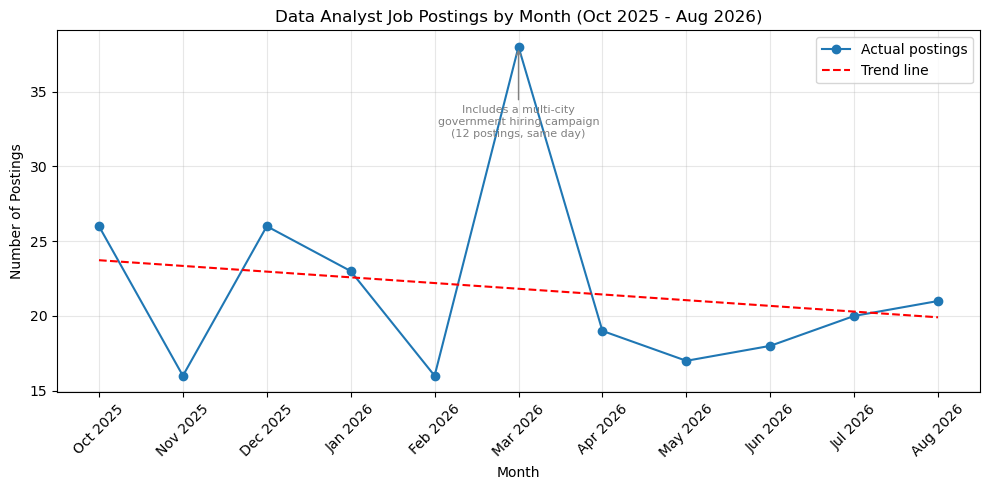

In [16]:
# Draw the fitted trend line over the actual data (y = slope * x + intercept for every month)
trend_line = slope * monthly_counts['Month_Index'] + intercept

plt.figure(figsize=(10, 5))
plt.plot(monthly_counts['Month_Label'], monthly_counts['Posting_Count'], marker='o', label='Actual postings')
plt.plot(monthly_counts['Month_Label'], trend_line, linestyle='--', color='red', label='Trend line')

plt.title('Data Analyst Job Postings by Month (Oct 2025 - Aug 2026)')
plt.xlabel('Month')
plt.ylabel('Number of Postings')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()

plt.annotate('Includes a multi-city\ngovernment hiring campaign\n(12 postings, same day)',
             xy=('Mar 2026', 38), xytext=('Mar 2026', 32),
             ha='center', fontsize=8, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray'))

plt.tight_layout()
plt.show()

In [17]:
# Investigate the March 2026 spike (38 postings vs. 16-26 in other months): pull out just March's rows
march_data = combined[combined['Month'] == 'Mar 2026']

# Which titles make up March? (28 of 38 are 'data analyst - informatics and systems')
print(march_data['Job Title'].value_counts())
print()

# Which posting dates? (12 of them on 2026/03/25 alone -> a batch posting, not steady demand)
print(march_data['First Posting Date'].value_counts().sort_index())

data analyst - informatics and systems    28
big data analyst                           5
business data analyst                      4
marketing data analyst                     1
Name: Job Title, dtype: int64

2026/03/01     2
2026/03/02     3
2026/03/04     1
2026/03/06     1
2026/03/08     1
2026/03/13     2
2026/03/15     2
2026/03/17     1
2026/03/18     1
2026/03/20     1
2026/03/21     3
2026/03/22     1
2026/03/23     1
2026/03/24     1
2026/03/25    12
2026/03/26     3
2026/03/28     1
2026/03/29     1
Name: First Posting Date, dtype: int64


In [18]:
# Sensitivity check: does the March spike drive the downward slope?
# Copy first so the original table is untouched, then remove the 12 same-day campaign postings from March.
adjusted_counts = monthly_counts.copy()
adjusted_counts.loc[adjusted_counts['Month_Label'] == 'Mar 2026', 'Posting_Count'] -= 12

adj_slope, adj_intercept = np.polyfit(adjusted_counts['Month_Index'], adjusted_counts['Posting_Count'], 1)

print(f"Original slope:  {slope:.2f} postings/month")
print(f"Adjusted slope:  {adj_slope:.2f} postings/month (with campaign spike removed)")

# The slopes are identical because March is the middle month (index 5 of 0-10):
# a point at the center of the x-axis can move the line up or down, but cannot tilt it.

Original slope:  -0.38 postings/month
Adjusted slope:  -0.38 postings/month (with campaign spike removed)


## 5. Salary analysis (11 months)

The raw data has structured salary columns: `Salary Per` (Hour / Year / Month / Bi-weekly), `Salary Minimum`, `Salary Maximum`. We average min and max per posting, then convert everything to an annual figure so rows are comparable.

In [19]:
# Separate pass over the files (independent of `combined`), keeping the salary columns.
salary_rows = []

for f in files_11:
    df = load_one_file(f)
    mask = df['Job Title'].str.contains('data analyst', case=False, na=False)
    filtered = df.loc[mask, ['Job Title', 'First Posting Date', 'Salary Per', 'Salary Minimum', 'Salary Maximum']].copy()
    filtered.insert(0, 'Month', get_month_label_v2(f.name))
    salary_rows.append(filtered)

salary_data = pd.concat(salary_rows, ignore_index=True)
print('Total rows:', len(salary_data))
salary_data.head(10)

/var/folders/x0/tnq06mms319gftqmck0wk0m80000gn/T/ipykernel_2286/267743930.py:11: DtypeWarning: Columns (57,58) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, encoding=encoding, sep=sep)


Total rows: 240


,Month,Job Title,First Posting Date,Salary Per,Salary Minimum,Salary Maximum
0,Apr 2026,big data analyst,2026/04/23,Hour,20.34,26.00
1,Apr 2026,data analyst - informatics and systems,2026/04/10,Hour,36.02,36.02
2,Apr 2026,business data analyst,2026/04/23,Hour,43.00,43.00
3,Apr 2026,big data analyst,2026/04/21,Year,55000.00,55000.00
4,Apr 2026,data analyst - informatics and systems,2026/04/13,Hour,54.87,54.87
5,Apr 2026,business data analyst,2026/04/07,Bi-weekly,3410.48,4005.58
6,Apr 2026,data analyst - informatics and systems,2026/04/24,Hour,20.00,20.00
7,Apr 2026,data analyst - informatics and systems,2026/04/06,Hour,25.00,61.03
8,Apr 2026,big data analyst,2026/04/16,Year,80000.00,100000.00
9,Apr 2026,data analyst - informatics and systems,2026/04/29,Hour,44.50,44.50


In [20]:
# Per-posting midpoint of the pay range. Valid within a row regardless of unit.
salary_data['Salary_Avg'] = (salary_data['Salary Minimum'] + salary_data['Salary Maximum']) / 2

# Which pay units exist? (Hour, Year, Bi-weekly, Month -- plus a few blanks)
print(salary_data['Salary Per'].value_counts())

Hour         147
Year          79
Bi-weekly      6
Month          4
Name: Salary Per, dtype: int64


In [21]:
# Convert every row to an annual figure so hourly, monthly, bi-weekly and yearly pay are comparable.
#   Hour      -> x 1950  (assumption: 37.5 hours/week x 52 weeks; state this in the write-up)
#   Month     -> x 12
#   Bi-weekly -> x 26   (26 pay periods a year)
#   Year      -> unchanged
def to_annual(row):
    if row['Salary Per'] == 'Hour':
        return row['Salary_Avg'] * 1950
    elif row['Salary Per'] == 'Month':
        return row['Salary_Avg'] * 12
    elif row['Salary Per'] == 'Bi-weekly':
        return row['Salary_Avg'] * 26
    elif row['Salary Per'] == 'Year':
        return row['Salary_Avg']
    else:
        return None      # missing / unrecognized unit

# apply(..., axis=1) runs the function on every row
salary_data['Salary_Annual'] = salary_data.apply(to_annual, axis=1)
salary_data[['Salary Per', 'Salary_Avg', 'Salary_Annual']].head(10)

,Salary Per,Salary_Avg,Salary_Annual
0,Hour,23.170,45181.50
1,Hour,36.020,70239.00
2,Hour,43.000,83850.00
3,Year,55000.000,55000.00
4,Hour,54.870,106996.50
5,Bi-weekly,3708.030,96408.78
6,Hour,20.000,39000.00
7,Hour,43.015,83879.25
8,Year,90000.000,90000.00
9,Hour,44.500,86775.00


In [22]:
# How many rows have no usable salary? (4 expected: postings with no salary listed)
salary_data['Salary_Annual'].isna().sum()

4

In [23]:
# First monthly salary table (this version still contains one bad row -- see the next cells)
salary_data['Month_Date'] = pd.to_datetime(salary_data['Month'], format='%b %Y')

# .agg() computes several things per group in one step.
# Posting_Count is the number of postings WITH a salary, so we can see how reliable each month's average is.
monthly_salary = salary_data.groupby('Month_Date').agg(
    Salary_Avg_Annual=('Salary_Annual', 'mean'),
    Posting_Count=('Salary_Annual', 'count')
).reset_index()

monthly_salary = monthly_salary.sort_values('Month_Date')
monthly_salary['Month_Label'] = monthly_salary['Month_Date'].dt.strftime('%b %Y')
monthly_salary

,Month_Date,Salary_Avg_Annual,Posting_Count,Month_Label
0,2025-10-01,76563.781250,24,Oct 2025
1,2025-11-01,81318.048214,14,Nov 2025
2,2025-12-01,82177.519231,26,Dec 2025
3,2026-01-01,83745.197826,23,Jan 2026
4,2026-02-01,77697.290313,16,Feb 2026
5,2026-03-01,218493.833684,38,Mar 2026
6,2026-04-01,79199.705789,19,Apr 2026
7,2026-05-01,91142.627059,17,May 2026
8,2026-06-01,77541.444444,18,Jun 2026
9,2026-07-01,77669.709500,20,Jul 2026


In [24]:
# March 2026 averaged ~$218K, about 3x every other month. Look at the individual March salaries, highest first.
march_salary = salary_data[salary_data['Month'] == 'Mar 2026']
march_salary[['Job Title', 'Salary Per', 'Salary Minimum', 'Salary Maximum', 'Salary_Annual']].sort_values('Salary_Annual', ascending=False)

# One posting lists a maximum of $5,308.29 per HOUR (min $34.90) -> ~$5.2 million a year. That is a data entry error.

,Job Title,Salary Per,Salary Minimum,Salary Maximum,Salary_Annual
161,data analyst - informatics and systems,Hour,34.90,5308.29,5209610.25
156,data analyst - informatics and systems,Hour,62.26,62.26,121407.00
146,business data analyst,Bi-weekly,3850.00,3850.00,100100.00
148,business data analyst,Hour,48.10,48.10,93795.00
165,business data analyst,Hour,48.10,48.10,93795.00
172,marketing data analyst,Hour,48.00,48.00,93600.00
149,big data analyst,Year,85000.00,100000.00,92500.00
143,data analyst - informatics and systems,Hour,45.00,45.00,87750.00
157,big data analyst,Hour,44.47,44.47,86716.50
177,data analyst - informatics and systems,Hour,43.96,43.96,85722.00


In [25]:
# Confirm that one row explains the spike: March's average with and without it
march_salary_fixed = march_salary[march_salary['Salary_Annual'] < 1000000]

print("March average WITH the outlier:   ", march_salary['Salary_Annual'].mean())
print("March average WITHOUT the outlier:", march_salary_fixed['Salary_Annual'].mean())

March average WITH the outlier:    218493.83368421052
March average WITHOUT the outlier: 83598.7954054054


In [26]:
# Apply the same sanity cutoff ($1M a year) to the whole table.
# This also drops rows with missing salary (None < 1000000 is False): expect 240 -> 235 (4 missing + 1 outlier).
salary_data_clean = salary_data[salary_data['Salary_Annual'] < 1000000]
print(f"Rows before: {len(salary_data)}, Rows after removing outlier(s): {len(salary_data_clean)}")

monthly_salary = salary_data_clean.groupby('Month_Date').agg(
    Salary_Avg_Annual=('Salary_Annual', 'mean'),
    Posting_Count=('Salary_Annual', 'count')
).reset_index()

monthly_salary = monthly_salary.sort_values('Month_Date')
monthly_salary['Month_Label'] = monthly_salary['Month_Date'].dt.strftime('%b %Y')
monthly_salary

Rows before: 240, Rows after removing outlier(s): 235


,Month_Date,Salary_Avg_Annual,Posting_Count,Month_Label
0,2025-10-01,76563.781250,24,Oct 2025
1,2025-11-01,81318.048214,14,Nov 2025
2,2025-12-01,82177.519231,26,Dec 2025
3,2026-01-01,83745.197826,23,Jan 2026
4,2026-02-01,77697.290313,16,Feb 2026
5,2026-03-01,83598.795405,37,Mar 2026
6,2026-04-01,79199.705789,19,Apr 2026
7,2026-05-01,91142.627059,17,May 2026
8,2026-06-01,77541.444444,18,Jun 2026
9,2026-07-01,77669.709500,20,Jul 2026


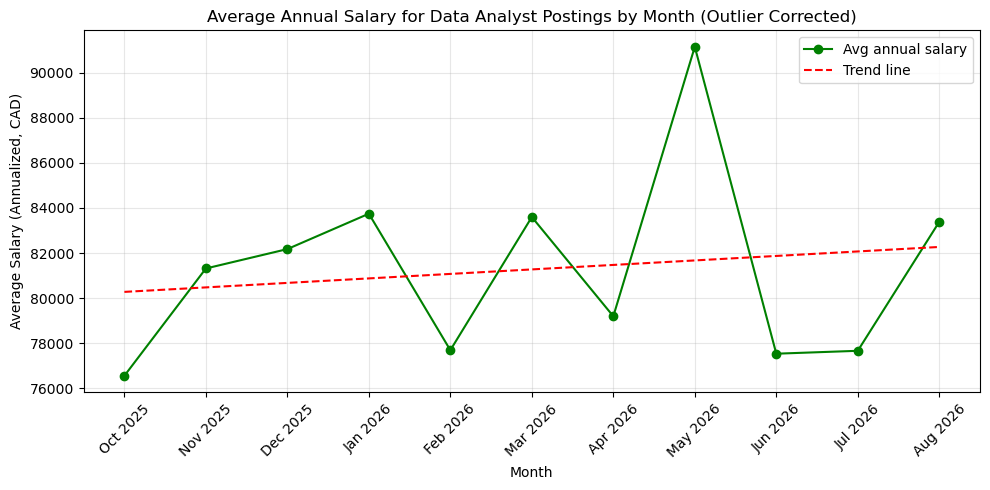

Salary slope: $199 per month


In [27]:
# Salary trend: same straight-line fit as the postings trend, on the cleaned monthly averages
monthly_salary['Month_Index'] = range(len(monthly_salary))
salary_slope, salary_intercept = np.polyfit(monthly_salary['Month_Index'], monthly_salary['Salary_Avg_Annual'], 1)
salary_trend_line = salary_slope * monthly_salary['Month_Index'] + salary_intercept

plt.figure(figsize=(10, 5))
plt.plot(monthly_salary['Month_Label'], monthly_salary['Salary_Avg_Annual'], marker='o', color='green', label='Avg annual salary')
plt.plot(monthly_salary['Month_Label'], salary_trend_line, linestyle='--', color='red', label='Trend line')
plt.title('Average Annual Salary for Data Analyst Postings by Month (Outlier Corrected)')
plt.xlabel('Month')
plt.ylabel('Average Salary (Annualized, CAD)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Salary slope: ${salary_slope:,.0f} per month")   # about +$199 per month

## 6. Does job-title mix explain the salary rise?

If higher-paying titles became a bigger share of postings later in the period, average pay could rise without any individual role paying more.

In [28]:
# Average salary and number of postings per job title, highest paying first.
# Titles with count = 1 are single postings and not reliable averages.
salary_data_clean.groupby('Job Title')['Salary_Annual'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
Job Title,,
Geoscience Data Analyst,101672.000000,1
marketing data analyst,93185.625000,4
business data analyst,88297.625806,31
"Data Analyst, IT Software Solutions",85854.000000,1
"Information Technology (IT) Data Analyst, IT Software Solutions",85854.000000,1
data analyst - informatics and systems,83951.845145,138
"Data Analyst, Senior Data Analyst and Data Advisor - Inventory",83862.000000,1
information technology (IT) data analyst,80739.830000,2
"Data Analyst, Regulatory Reporting",73511.000000,1


In [29]:
# Is there an Experience Level (seniority) column we could use instead? Look for related column names.
df_sample = load_one_file(data_folder / 'aug_2026.csv')
print([col for col in df_sample.columns if 'Experience' in col or 'Skill' in col or 'Education' in col])

['Education LOS', 'Experience Level']


In [30]:
# 'Experience Level' exists. How complete is it for Data Analyst postings, file by file?
missing_counts = []

for f in files_11:
    df_temp = load_one_file(f)
    mask_temp = df_temp['Job Title'].str.contains('data analyst', case=False, na=False)
    total = mask_temp.sum()
    missing = df_temp.loc[mask_temp, 'Experience Level'].isna().sum()
    missing_counts.append({'File': f.name, 'Total_DA_Rows': total, 'Missing_Experience': missing})

pd.DataFrame(missing_counts)   # ~82% missing overall -> not usable, so we fall back to Job Title as the proxy

/var/folders/x0/tnq06mms319gftqmck0wk0m80000gn/T/ipykernel_2286/267743930.py:11: DtypeWarning: Columns (57,58) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, encoding=encoding, sep=sep)


,File,Total_DA_Rows,Missing_Experience
0,april_2026.csv,19,15
1,aug_2026.csv,21,14
2,dec_2025.csv,26,23
3,feb_2026.csv,16,15
4,jan_2026.csv,23,18
5,july_2026.csv,20,18
6,june_2026.csv,18,12
7,march_2026.csv,38,32
8,may_2026.csv,17,13
9,nov_2025.csv,16,14


In [31]:
# Count postings per month per job title.
#   groupby([...]).size()  -> counts for each month/title pair
#   .unstack(fill_value=0) -> months become rows, titles become columns, gaps filled with 0
#   .reindex(...)          -> put the rows back in chronological order
monthly_title_mix = salary_data_clean.groupby(['Month', 'Job Title']).size().unstack(fill_value=0)
monthly_title_mix = monthly_title_mix.reindex(monthly_salary['Month_Label'])
monthly_title_mix

Job Title,Data Analyst,"Data Analyst, IT Software Solutions","Data Analyst, Regulatory Reporting","Data Analyst, Senior Data Analyst and Data Advisor - Inventory",Geoscience Data Analyst,"Information Technology (IT) Data Analyst, IT Software Solutions",Junior Data Analyst,big data analyst,business data analyst,data analyst - informatics and systems,information technology (IT) data analyst,marketing data analyst
Month_Label,,,,,,,,,,,,
Oct 2025,6,0,0,0,0,0,1,6,2,8,0,1
Nov 2025,0,0,0,0,0,0,0,4,1,8,0,1
Dec 2025,0,1,0,0,0,0,0,5,3,17,0,0
Jan 2026,0,0,0,0,0,0,0,4,1,17,0,1
Feb 2026,0,0,0,0,0,0,0,3,1,12,0,0
Mar 2026,0,0,0,0,0,0,0,5,4,27,0,1
Apr 2026,0,0,0,0,0,0,0,3,3,13,0,0
May 2026,0,0,0,0,0,0,0,3,4,10,0,0
Jun 2026,0,0,1,0,0,1,0,4,5,7,0,0


In [32]:
# Convert counts to percentage share per month for the 3 titles with real volume,
# so months with different totals can be compared fairly.
focus_titles = ['big data analyst', 'business data analyst', 'data analyst - informatics and systems']
mix_share = monthly_title_mix[focus_titles].div(monthly_title_mix[focus_titles].sum(axis=1), axis=0) * 100
mix_share.round(1)

# Finding: "business data analyst" (the highest-paying of the three) grew from roughly 5-12% of postings
# to 16-32% in the second half of the window -> part of the pay rise is a mix shift, not pure wage growth.
# Small counts, one job board, 11 months: treat as a soft signal, not a confirmed trend.

Job Title,big data analyst,business data analyst,data analyst - informatics and systems
Month_Label,,,
Oct 2025,37.5,12.5,50.0
Nov 2025,30.8,7.7,61.5
Dec 2025,20.0,12.0,68.0
Jan 2026,18.2,4.5,77.3
Feb 2026,18.8,6.2,75.0
Mar 2026,13.9,11.1,75.0
Apr 2026,15.8,15.8,68.4
May 2026,17.6,23.5,58.8
Jun 2026,25.0,31.2,43.8


## 7. Extending to 20 months (Jan 2025 - Aug 2026)

In [33]:
# 2025 files have 64 columns, 2026 files have 65. Which column differs?
# set(...) turns a column list into an unordered collection; set subtraction shows what is in one but not the other.
df_2025 = load_one_file(data_folder / 'jan_2025.csv')
df_2026 = load_one_file(data_folder / 'jan_2026.csv')

cols_2025 = set(df_2025.columns)
cols_2026 = set(df_2026.columns)

print("In 2026 but not 2025:", cols_2026 - cols_2025)   # only 'Official Language' -- not used in our analysis
print("In 2025 but not 2026:", cols_2025 - cols_2026)

In 2026 but not 2025: {'Official Language'}
In 2025 but not 2026: set()


In [34]:
# Total postings in each file vs. Data Analyst postings, so we can tell a market-wide shrink from a Data-Analyst-specific one.
rows = []

for f in files:
    df = load_one_file(f)
    mask = df['Job Title'].str.contains('data analyst', case=False, na=False)
    rows.append({
        'Month': get_month_label_v2(f.name),
        'Total_Postings': len(df),        # all rows in the file
        'DA_Postings': mask.sum()         # rows whose title contains "data analyst"
    })

volume = pd.DataFrame(rows)
volume['Month_Date'] = pd.to_datetime(volume['Month'], format='%b %Y')
volume = volume.sort_values('Month_Date').reset_index(drop=True)
volume['DA_Share_Pct'] = (volume['DA_Postings'] / volume['Total_Postings'] * 100).round(3)   # DA postings as % of all postings
volume

/var/folders/x0/tnq06mms319gftqmck0wk0m80000gn/T/ipykernel_2286/267743930.py:11: DtypeWarning: Columns (57,58) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, encoding=encoding, sep=sep)


,Month,Total_Postings,DA_Postings,Month_Date,DA_Share_Pct
0,Jan 2025,101570,161,2025-01-01,0.159
1,Feb 2025,94240,148,2025-02-01,0.157
2,Mar 2025,87785,120,2025-03-01,0.137
3,Apr 2025,68653,56,2025-04-01,0.082
4,May 2025,70284,63,2025-05-01,0.090
5,Jun 2025,68793,48,2025-06-01,0.070
6,Jul 2025,58692,29,2025-07-01,0.049
7,Aug 2025,56776,15,2025-08-01,0.026
8,Sep 2025,58310,23,2025-09-01,0.039
9,Oct 2025,53724,26,2025-10-01,0.048


In [35]:
# Jan-Mar 2025 has 120-161 Data Analyst postings a month vs. ~20 later. Is one title responsible?
early = combined_full[combined_full['Month_Date'] <= '2025-03-01']
print(early['Job Title'].value_counts().head(10))     # 390 of 429 are 'data analyst - informatics and systems'
print()
print(early['First Posting Date'].value_counts().head(5))

data analyst - informatics and systems                                     390
big data analyst                                                            18
business data analyst                                                       10
marketing data analyst                                                       6
Data Analyst / Data Scientist – Post-secondary Recruitment                   2
information technology (IT) data analyst                                     2
Junior Data Analyst /Junior Data Scientist - Post-secondary Recruitment      1
Name: Job Title, dtype: int64

2025/01/29    15
2025/01/31    14
2025/01/08    13
2025/02/04    12
2025/01/15    11
Name: First Posting Date, dtype: int64


In [36]:
# Tag each row: True if the title is exactly the repeated pool title, False otherwise.
#   .str.lower() lowercases the title so capital letters cannot break the match
#   == '...' is an exact comparison (unlike .str.contains, which matches any title containing the text)
combined_full['Is_Informatics'] = combined_full['Job Title'].str.lower() == 'data analyst - informatics and systems'

# Count per month and per group; False (other titles) sorts before True (informatics), so name the columns in that order
monthly_split = combined_full.groupby(['Month_Date', 'Is_Informatics']).size().unstack(fill_value=0)
monthly_split.columns = ['Other_DA', 'Informatics_Systems']
monthly_split['Total'] = monthly_split.sum(axis=1)      # should match the Data Analyst counts per month
monthly_split

,Other_DA,Informatics_Systems,Total
Month_Date,,,
2025-01-01,11,150,161
2025-02-01,19,129,148
2025-03-01,9,111,120
2025-04-01,13,43,56
2025-05-01,13,50,63
2025-06-01,11,37,48
2025-07-01,13,16,29
2025-08-01,9,6,15
2025-09-01,13,10,23


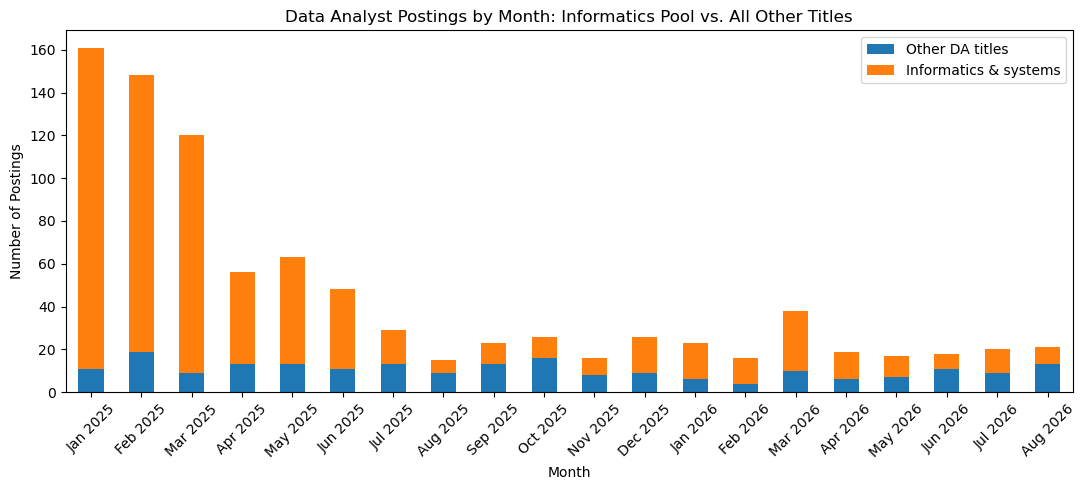

In [37]:
# Stacked bar chart: how much of each month's total is the informatics pool vs. everything else.
# Run this cell once: it replaces the date index with text labels.
monthly_split.index = monthly_split.index.strftime('%b %Y')

monthly_split[['Other_DA', 'Informatics_Systems']].plot(kind='bar', stacked=True, figsize=(11, 5))
plt.title('Data Analyst Postings by Month: Informatics Pool vs. All Other Titles')
plt.xlabel('Month')
plt.ylabel('Number of Postings')
plt.xticks(rotation=45)
plt.legend(['Other DA titles', 'Informatics & systems'])
plt.tight_layout()
plt.show()

In [38]:
# The last 12 months (the stable period). iloc[-12:] means "the last 12 rows".
recent = monthly_split.iloc[-12:]

def backtest(series, holdout=4):
    # Split: train on everything except the last `holdout` months, then try to predict those months.
    train = series.iloc[:-holdout]
    test = series.iloc[-holdout:]

    # Method 3 needs a numeric time axis, same idea as Month_Index earlier.
    # polyfit on the training months only, then extend the line into the held-out months.
    m, b = np.polyfit(np.arange(len(train)), train.values, 1)
    trend_pred = m * np.arange(len(train), len(series)) + b

    predictions = {
        'Naive (repeat last month)': np.repeat(train.iloc[-1], holdout),   # method 1: next months = most recent month
        'Average of training months': np.repeat(train.mean(), holdout),    # method 2: next months = historical average
        'Linear trend': trend_pred,                                        # method 3: keep drawing the fitted line
    }

    print('Actual held-out months:', test.values.tolist())
    for name, pred in predictions.items():
        # MAE = mean absolute error: on average, how many postings each month the forecast was off by
        mae = np.mean(np.abs(test.values - pred))
        print(f"{name:28} MAE = {mae:.1f}")

for col in ['Total', 'Other_DA']:
    print(col)
    backtest(recent[col])
    print()

Total
Actual held-out months: [17, 18, 20, 21]
Naive (repeat last month)    MAE = 1.5
Average of training months   MAE = 4.4
Linear trend                 MAE = 6.4

Other_DA
Actual held-out months: [7, 11, 9, 13]
Naive (repeat last month)    MAE = 4.0
Average of training months   MAE = 2.0
Linear trend                 MAE = 7.7



In [39]:
future_months = ['Sep 2026', 'Oct 2026', 'Nov 2026', 'Dec 2026']

# Total: naive method -> repeat the latest month (Aug 2026)
total_level = recent['Total'].iloc[-1]
# Other_DA: average method -> mean of the last 12 months
other_level = recent['Other_DA'].mean()

forecast = pd.DataFrame({
    'Month': future_months,
    'Total_forecast': total_level,
    'Total_low': total_level - 1.5,      # 1.5 = backtest MAE for Total
    'Total_high': total_level + 1.5,
    'Other_DA_forecast': round(other_level, 1),
    'Other_DA_low': round(other_level - 2.0, 1),   # 2.0 = backtest MAE for Other_DA
    'Other_DA_high': round(other_level + 2.0, 1),
})
forecast

,Month,Total_forecast,Total_low,Total_high,Other_DA_forecast,Other_DA_low,Other_DA_high
0,Sep 2026,21,19.5,22.5,9.3,7.3,11.3
1,Oct 2026,21,19.5,22.5,9.3,7.3,11.3
2,Nov 2026,21,19.5,22.5,9.3,7.3,11.3
3,Dec 2026,21,19.5,22.5,9.3,7.3,11.3


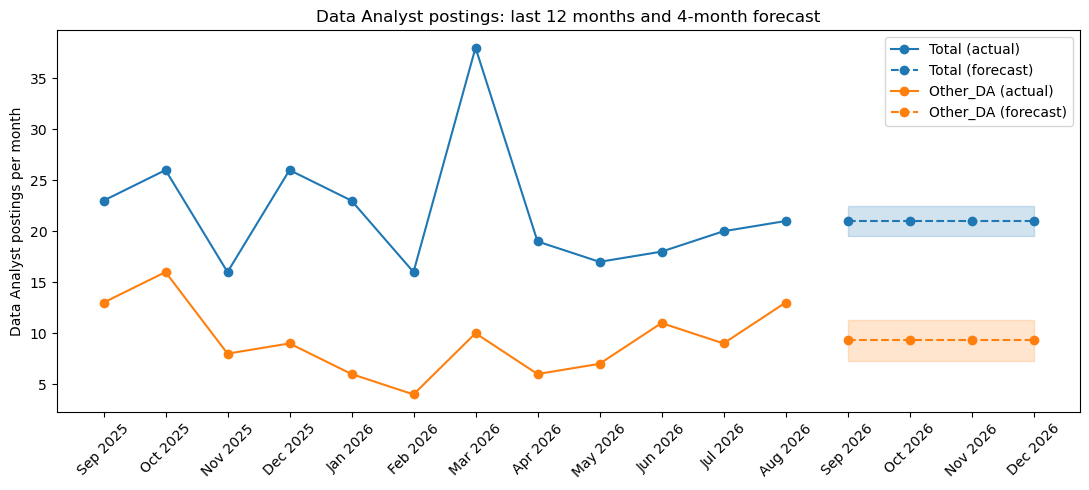

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

# x positions: 0..11 for history, 12..15 for the forecast
x_hist = list(range(len(recent)))
x_fut = list(range(len(recent), len(recent) + 4))

# Total: actual line, dashed forecast line, shaded range
ax.plot(x_hist, recent['Total'], marker='o', color='C0', label='Total (actual)')
ax.plot(x_fut, forecast['Total_forecast'], marker='o', linestyle='--', color='C0', label='Total (forecast)')
ax.fill_between(x_fut, forecast['Total_low'], forecast['Total_high'], color='C0', alpha=0.2)

# Other_DA: same idea in a second colour
ax.plot(x_hist, recent['Other_DA'], marker='o', color='C1', label='Other_DA (actual)')
ax.plot(x_fut, forecast['Other_DA_forecast'], marker='o', linestyle='--', color='C1', label='Other_DA (forecast)')
ax.fill_between(x_fut, forecast['Other_DA_low'], forecast['Other_DA_high'], color='C1', alpha=0.2)

# Replace the numbers on the x-axis with month names
labels = list(recent.index) + future_months
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45)

ax.set_ylabel('Data Analyst postings per month')
ax.set_title('Data Analyst postings: last 12 months and 4-month forecast')
ax.legend()
plt.tight_layout()
plt.show()

In [41]:
for col in ['Total', 'Other_DA']:
    s = recent[col]
    print(col)
    print('  mean =', round(s.mean(), 1))
    print('  std  =', round(s.std(), 1))
    print('  min  =', s.min(), ' max =', s.max())

Total
  mean = 21.9
  std  = 6.2
  min  = 16  max = 38
Other_DA
  mean = 9.3
  std  = 3.5
  min  = 4  max = 16


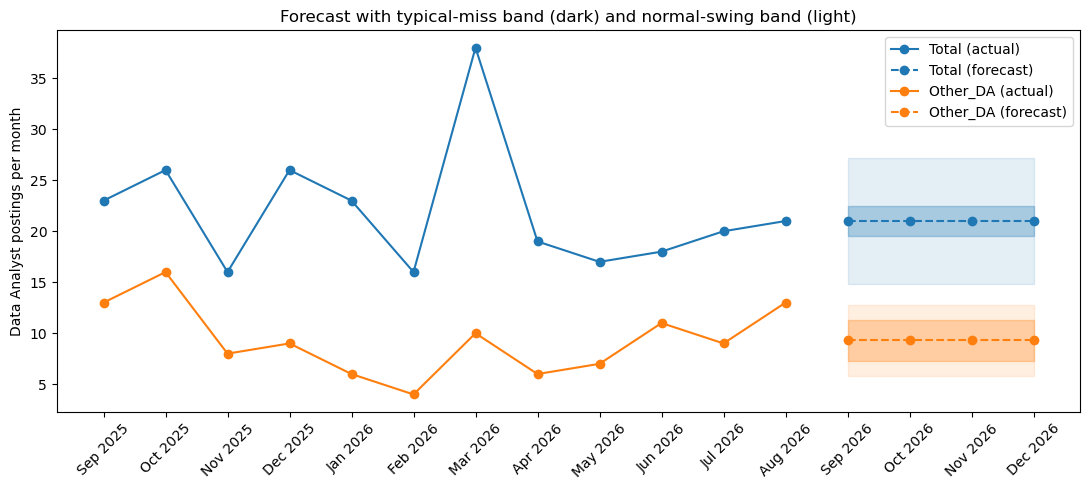

In [42]:
# Wide band = forecast level ± 1 standard deviation of the last 12 months
forecast['Total_wide_low'] = forecast['Total_forecast'] - 6.2
forecast['Total_wide_high'] = forecast['Total_forecast'] + 6.2
forecast['Other_DA_wide_low'] = forecast['Other_DA_forecast'] - 3.5
forecast['Other_DA_wide_high'] = forecast['Other_DA_forecast'] + 3.5

fig, ax = plt.subplots(figsize=(11, 5))

x_hist = list(range(len(recent)))
x_fut = list(range(len(recent), len(recent) + 4))

# Total
ax.plot(x_hist, recent['Total'], marker='o', color='C0', label='Total (actual)')
ax.plot(x_fut, forecast['Total_forecast'], marker='o', linestyle='--', color='C0', label='Total (forecast)')
ax.fill_between(x_fut, forecast['Total_wide_low'], forecast['Total_wide_high'], color='C0', alpha=0.12)
ax.fill_between(x_fut, forecast['Total_low'], forecast['Total_high'], color='C0', alpha=0.3)

# Other_DA
ax.plot(x_hist, recent['Other_DA'], marker='o', color='C1', label='Other_DA (actual)')
ax.plot(x_fut, forecast['Other_DA_forecast'], marker='o', linestyle='--', color='C1', label='Other_DA (forecast)')
ax.fill_between(x_fut, forecast['Other_DA_wide_low'], forecast['Other_DA_wide_high'], color='C1', alpha=0.12)
ax.fill_between(x_fut, forecast['Other_DA_low'], forecast['Other_DA_high'], color='C1', alpha=0.3)

labels = list(recent.index) + future_months
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45)

ax.set_ylabel('Data Analyst postings per month')
ax.set_title('Forecast with typical-miss band (dark) and normal-swing band (light)')
ax.legend()
plt.tight_layout()
plt.show()